# 01 · Comprensión de los datos: problema de BCS

Los datos se descargan del bucket de S3 del reto con boto3, usando una llave de acceso de AWS. Antes de correr el notebook hay que definir estas variables de entorno (en Colab, como secretos con el mismo nombre):

- `S3_BUCKET`: nombre del bucket.
- `AWS_KEY_ID`: ID de la llave de acceso.
- `AWS_SECRET`: secreto de la llave de acceso.

## Configuración

In [1]:
%pip install -q boto3 pillow-heif
import os
import boto3

try:
    from google.colab import userdata
    for nombre in ("S3_BUCKET", "AWS_KEY_ID", "AWS_SECRET"):
        os.environ[nombre] = userdata.get(nombre)
except ImportError:
    pass

BUCKET = os.environ["S3_BUCKET"]
s3 = boto3.client(
    "s3",
    region_name="mx-central-1",
    aws_access_key_id=os.environ["AWS_KEY_ID"],
    aws_secret_access_key=os.environ["AWS_SECRET"],
)

PREFIJO_FOTOS = "bcs/originales/fotosextraidas/"
KEY_BITACORA = "bcs/originales/etiquetas_bsc.xlsx"
KEY_VMS3 = "data/csv/VACAS VMS 3 CONDICION CORPORAL.csv"
PREFIJO_ORDENOS = "ordenos/"

In [2]:
from pathlib import Path


def carpeta_de_datos():
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / ".git").exists():
            return carpeta / "data"
    return Path.cwd() / "data"


DESTINO = carpeta_de_datos()


def listar(prefijo):
    """Todas las llaves del bucket bajo un prefijo."""
    for pagina in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix=prefijo):
        for o in pagina.get("Contents", []):
            if not o["Key"].endswith("/"):
                yield o["Key"]


def bajar(key, destino):
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    if not destino.exists():
        s3.download_file(BUCKET, key, str(destino))


data = DESTINO
for key in listar(PREFIJO_FOTOS):
    bajar(key, data / "fotosextraidas" / key[len(PREFIJO_FOTOS):])
bajar(KEY_BITACORA, data / "etiquetas_bsc.xlsx")
bajar(KEY_VMS3, data / "csv" / "vms-3.csv")
for key in listar(PREFIJO_ORDENOS):
    nombre = key[len(PREFIJO_ORDENOS):]
    if "/" not in nombre and nombre.endswith(".csv"):
        bajar(key, data / "csv" / nombre)
print(f"Datos listos en {data}")

Datos listos en /content/data


In [3]:
from pathlib import Path
from collections import Counter
import datetime as dt
import hashlib
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openpyxl import load_workbook
from PIL import Image

try:
    import pillow_heif
    pillow_heif.register_heif_opener()
    LEE_HEIC = True
except ImportError:
    LEE_HEIC = False

RAIZ = Path(DESTINO)
DIR_FOTOS = RAIZ / "fotosextraidas"
BITACORA = RAIZ / "etiquetas_bsc.xlsx"
DIR_CSV = RAIZ / "csv"
VMS3 = DIR_CSV / "vms-3.csv"

FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

pd.set_option("display.max_rows", 120)
for p in (DIR_FOTOS, BITACORA, DIR_CSV, VMS3):
    print("OK       " if p.exists() else "NO EXISTE", p)
print("Lectura de HEIC:", "sí" if LEE_HEIC else "no (instala pillow-heif)")

OK        /content/data/fotosextraidas
OK        /content/data/etiquetas_bsc.xlsx
OK        /content/data/csv
OK        /content/data/csv/vms-3.csv
Lectura de HEIC: sí


### Funciones auxiliares

In [4]:
def sha256(ruta, bloque=1 << 20):
    """Huella del contenido del archivo: dos archivos con la misma huella son idénticos."""
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for b in iter(lambda: f.read(bloque), b""):
            h.update(b)
    return h.hexdigest()


def metadatos(ruta):
    """Tamaño, cámara, fecha, orientación y profundidad de una foto (sin decodificar los píxeles)."""
    r = {"ancho": None, "alto": None, "camara": "", "fecha": "", "orientacion": None,
         "profundidad": False, "error": ""}
    try:
        with Image.open(ruta) as im:
            exif = im.getexif()
            r["ancho"], r["alto"] = im.size
            r["camara"] = f"{exif.get(0x010F, '')} {exif.get(0x0110, '')}".strip()
            fecha = exif.get_ifd(0x8769).get(0x9003) or exif.get(0x0132) or ""
            r["fecha"] = str(fecha)[:10].replace(":", "-")
            r["orientacion"] = exif.get(0x0112)
            r["profundidad"] = bool(im.info.get("depth_images"))
    except Exception as e:
        r["error"] = str(e)[:120]
    return r


def norm(texto):
    """Nombre de columna en minúsculas, sin acentos ni símbolos ('ID - VACA' -> 'idvaca')."""
    t = str(texto).lower().translate(str.maketrans("áéíóúüñ", "aeiouun"))
    return re.sub(r"[^a-z0-9]", "", t)


def texto(v):
    """Celda de Excel a texto (1221.0 -> '1221', una hora -> 'HH MM')."""
    if v is None:
        return ""
    if isinstance(v, float) and v.is_integer():
        return str(int(v))
    if isinstance(v, (dt.time, dt.datetime)):
        return v.strftime("%H %M")
    return str(v).strip()


def clave(x):
    """Ordena los IDs como números cuando lo son."""
    return (0, int(x)) if str(x).isdigit() else (1, str(x))


def ordenar_ids(ids):
    return sorted(ids, key=clave)

## 2.1 Recolectar los datos iniciales

### Inventario de las fuentes

In [5]:
EXT_FOTO = {".heic", ".heif", ".jpg", ".jpeg", ".png"}
filas = []
for p in sorted(DIR_FOTOS.rglob("*")):
    if p.is_file() and p.suffix.lower() in EXT_FOTO and not p.name.startswith("."):
        rel = p.relative_to(DIR_FOTOS)
        filas.append({"id_vaca": p.parent.name.strip(), "descarga": rel.parts[0],
                      "archivo": p.name, "ruta": str(rel), "ext": p.suffix.lower(),
                      "bytes": p.stat().st_size, "sha256": sha256(p)})
fotos = pd.DataFrame(filas)
fotos = pd.concat([fotos, pd.DataFrame([metadatos(DIR_FOTOS / r) for r in fotos["ruta"]])], axis=1)

csv_ordeno = sorted(p for p in DIR_CSV.rglob("*.csv") if p.stem.strip().isdigit())
ids_ordeno = {p.stem.strip() for p in csv_ordeno}

fuentes = pd.DataFrame([
    {"fuente": "Fotos (fotosextraidas/)", "archivos": len(fotos), "MB": fotos["bytes"].sum() / 1e6},
    {"fuente": "Bitácora de expertos (etiquetas_bsc.xlsx)", "archivos": 1, "MB": BITACORA.stat().st_size / 1e6},
    {"fuente": "Dataset VMS 3 (vms-3.csv)", "archivos": 1, "MB": VMS3.stat().st_size / 1e6},
    {"fuente": "CSV de ordeño (uno por vaca)", "archivos": len(csv_ordeno),
     "MB": sum(p.stat().st_size for p in csv_ordeno) / 1e6},
]).round({"MB": 2})
display(fuentes)

,fuente,archivos,MB
0,Fotos (fotosextraidas/),477,1112.35
1,Bitácora de expertos (etiquetas_bsc.xlsx),1,0.03
2,Dataset VMS 3 (vms-3.csv),1,0.00
3,CSV de ordeño (uno por vaca),34,1.13


**Resultados:** Recibimos 477 archivos de fotos (1112.35 MB), la bitácora de expertos (0.03 MB), el dataset `vms-3.csv` y 34 CSV de ordeño, uno por vaca.

### Bitácora de expertos

In [6]:
wb = load_workbook(BITACORA, read_only=True, data_only=True)
hoja, fila_enc = None, None
for ws in wb.worksheets:
    for i, fila in enumerate(ws.iter_rows(min_row=1, max_row=40, values_only=True), start=1):
        nombres = [norm(v) for v in fila if v not in (None, "")]
        if any(n.startswith("id") for n in nombres) and any(n.startswith("bcs") for n in nombres):
            hoja, fila_enc = ws, i
            break
    if hoja is not None:
        break
nombre_hoja = hoja.title
filas = list(hoja.iter_rows(min_row=fila_enc, values_only=True))
wb.close()

encabezado = [texto(c) or f"(columna {i + 1})" for i, c in enumerate(filas[0])]
datos = []
for num, fila in enumerate(filas[1:], start=fila_enc + 1):
    valores = [texto(c) for c in fila][:len(encabezado)]
    if any(valores):
        datos.append([num] + valores + [""] * (len(encabezado) - len(valores)))
bit_raw = pd.DataFrame(datos, columns=["fila_excel"] + encabezado)


def columna(df, *prefijos):
    for c in df.columns:
        if c != "fila_excel" and any(norm(c).startswith(p) for p in prefijos):
            return c
    raise KeyError(f"No encontré una columna que empiece con {prefijos}")


c_id, c_hora, c_bcs = columna(bit_raw, "idvaca", "id"), columna(bit_raw, "hora"), columna(bit_raw, "bcs")
bit = pd.DataFrame({
    "fila_excel": bit_raw["fila_excel"],
    "id_vaca": bit_raw[c_id].str.replace(r"\.0$", "", regex=True),
    "hora_original": bit_raw[c_hora],
    "bcs": pd.to_numeric(bit_raw[c_bcs].str.replace(",", "."), errors="coerce"),
})
print(f"Bitácora: hoja '{nombre_hoja}', encabezados en la fila {fila_enc}, {len(bit)} filas")
print("Columnas:", [c for c in bit_raw.columns if c != "fila_excel"])

Bitácora: hoja 'Hoja 1', encabezados en la fila 2, 83 filas
Columnas: ['(columna 1)', 'ID - VACA', 'Hora / minuto', 'BCS', 'Cola', 'Foto', 'Carpeta', '(columna 8)', '(columna 9)']


**Resultados:** La bitácora está en la hoja "Hoja 1", con los encabezados en la fila 2. Tiene 83 filas y las columnas "ID - VACA", "Hora / minuto", "BCS", "Cola", "Foto" y "Carpeta", además de tres columnas sin nombre (la 1, la 8 y la 9).

### Dataset VMS 3

In [7]:
def leer_csv(ruta):
    for enc in ("utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(ruta, sep=None, engine="python", encoding=enc,
                               dtype=str, keep_default_na=False)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No pude leer {ruta}")


vms = leer_csv(VMS3)
vms.columns = [str(c).strip() for c in vms.columns]
columnas_vms = list(vms.columns)
c_vms_id = next((c for c in columnas_vms if norm(c).startswith("numerodelanimal")), columnas_vms[0])
c_evento = next((c for c in columnas_vms if "eventobcs" in norm(c)), None)
vms["id_vaca"] = vms[c_vms_id].str.strip().str.replace(r"\.0$", "", regex=True)
print(f"vms-3.csv: {len(vms)} filas y {len(columnas_vms)} columnas")
print(f"ID de la vaca: '{c_vms_id}' | Evento BCS: '{c_evento}'")
print(f"CSV de ordeño: {len(csv_ordeno)} vacas")

vms-3.csv: 24 filas y 16 columnas
ID de la vaca: 'Número del animal' | Evento BCS: 'Evento BCS'
CSV de ordeño: 34 vacas


**Resultados:** `vms-3.csv` tiene 24 filas (una por vaca) y 16 columnas.

## 2.2 Describir los datos

### Bitácora de expertos

In [8]:
hora = bit["hora_original"].str.strip()
formato_hora = pd.Series(np.select(
    [hora.str.lower().eq("x"), hora.str.match(r"^\d{1,2}\s\d{2}$")],
    ["x (sin dato)", "HH MM"], "otro formato"), index=bit.index)

resumen_bit = pd.Series({
    "evaluaciones (filas)": len(bit),
    "vacas distintas": bit["id_vaca"].nunique(),
    "vacas con más de una evaluación": int((bit["id_vaca"].value_counts() > 1).sum()),
    "BCS mínimo": bit["bcs"].min(),
    "BCS máximo": bit["bcs"].max(),
    "BCS promedio": round(bit["bcs"].mean(), 3),
    "BCS mediana": bit["bcs"].median(),
    "BCS desviación estándar": round(bit["bcs"].std(), 3),
    "todos en pasos de 0.25": bool(((bit["bcs"].dropna() * 4) % 1 == 0).all()),
}, dtype=object)
display(resumen_bit.to_frame("valor"))
display(formato_hora.value_counts().rename_axis("formato de la hora").to_frame("filas"))

,valor
evaluaciones (filas),83
vacas distintas,69
vacas con más de una evaluación,14
BCS mínimo,2.25
BCS máximo,3.75
BCS promedio,3.033
BCS mediana,3.0
BCS desviación estándar,0.39
todos en pasos de 0.25,True


,filas
formato de la hora,
HH MM,67
x (sin dato),14
otro formato,2


**Resultados:** Hay 83 evaluaciones de BCS de 69 vacas distintas; 14 vacas tienen más de una evaluación. El BCS va de 2.25 a 3.75 en pasos de 0.25, con promedio de 3.03 y mediana de 3.0. La hora está como "HH MM" en 67 filas, como "x" en 14 y con otro formato en 2.

### Fotografías

In [9]:
unicas = fotos.drop_duplicates("sha256")
resumen_fotos = pd.Series({
    "archivos": len(fotos),
    "fotos únicas": len(unicas),
    "tamaño total (GB)": round(fotos["bytes"].sum() / 1e9, 2),
    "tamaño sin copias (GB)": round(unicas["bytes"].sum() / 1e9, 2),
    "carpetas descargadas": fotos[["id_vaca", "descarga"]].drop_duplicates().shape[0],
    "vacas (IDs de carpeta)": fotos["id_vaca"].nunique(),
    "fotos con mapa de profundidad": int(unicas["profundidad"].sum()),
    "fotos que no se pudieron leer": int((unicas["error"] != "").sum()),
}, dtype=object)
display(resumen_fotos.to_frame("valor"))

display(unicas["ext"].value_counts().rename_axis("formato").to_frame("fotos únicas"))
display(unicas["camara"].replace("", "(sin dato)").value_counts().rename_axis("cámara").to_frame("fotos únicas"))
resolucion = unicas["ancho"].astype("Int64").astype(str) + " × " + unicas["alto"].astype("Int64").astype(str)
display(resolucion.value_counts().rename_axis("resolución (px)").to_frame("fotos únicas"))
display(unicas["fecha"].replace("", "(sin dato)").value_counts().rename_axis("fecha de captura").to_frame("fotos únicas"))

,valor
archivos,477
fotos únicas,351
tamaño total (GB),1.11
tamaño sin copias (GB),0.79
carpetas descargadas,83
vacas (IDs de carpeta),69
fotos con mapa de profundidad,74
fotos que no se pudieron leer,0


,fotos únicas
formato,
.heic,327
.jpg,24


,fotos únicas
cámara,
Apple iPhone 17 Pro Max,302
Apple iPhone XR,25
samsung SM-S901U1,24


,fotos únicas
resolución (px),
4284 × 5712,287
3024 × 4032,40
4000 × 3000,20
2984 × 4000,1
2911 × 4000,1
1599 × 2132,1
1458 × 1945,1


,fotos únicas
fecha de captura,
2026-10-14,351


**Resultados:** Hay 477 archivos (1.11 GB) y 351 fotos únicas (0.79 GB) de 69 vacas. Por formato: 327 HEIC y 24 JPG. Se tomaron con iPhone 17 Pro Max (302), iPhone XR (25) y Samsung SM-S901U1 (24), en 7 resoluciones distintas, la más común de 4284 × 5712 (287 fotos). 74 fotos traen mapa de profundidad.

### Fotos por vaca

In [10]:
por_vaca = fotos.drop_duplicates(["id_vaca", "sha256"]).groupby("id_vaca").size().rename("fotos únicas")
por_vaca = por_vaca.loc[ordenar_ids(por_vaca.index)]
display(por_vaca.describe().round(2).to_frame("fotos únicas por vaca"))
display(por_vaca.to_frame())

,fotos únicas por vaca
count,69.00
mean,5.14
std,3.08
min,1.00
25%,3.00
50%,4.00
75%,7.00
max,14.00


,fotos únicas
id_vaca,
1204,8
1221,9
1234,3
1240,1
1507,9
1510,13
1513,3
1516,9
1517,6


**Resultados:** Cada vaca tiene entre 1 y 14 fotos únicas, con una mediana de 4.

## 2.3 Explorar los datos

### Distribución del BCS

,evaluaciones,porcentaje
BCS,,
2.25,1,1.2
2.50,15,18.1
2.75,13,15.7
3.00,21,25.3
3.25,16,19.3
3.50,10,12.0
3.75,7,8.4


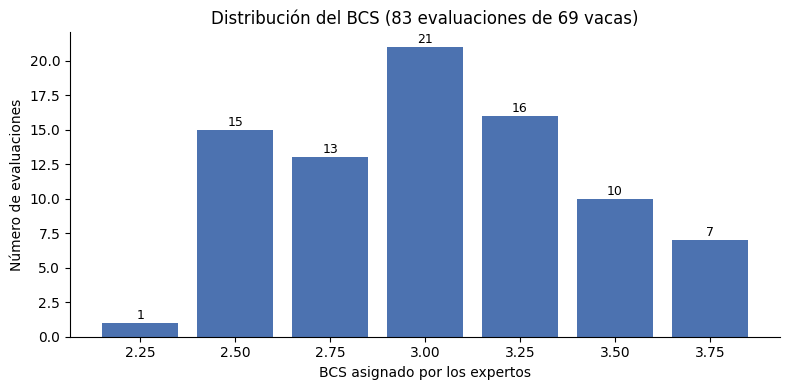

In [11]:
bcs_validos = bit["bcs"].dropna()
clases = np.arange(np.floor(bcs_validos.min() * 4) / 4, bcs_validos.max() + 0.125, 0.25)
conteo = bcs_validos.value_counts().reindex(clases, fill_value=0)
tabla_clases = pd.DataFrame({
    "evaluaciones": conteo.values,
    "porcentaje": (100 * conteo / conteo.sum()).round(1).values,
}, index=pd.Index([f"{c:.2f}" for c in clases], name="BCS"))
display(tabla_clases)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tabla_clases.index, tabla_clases["evaluaciones"], color="#4C72B0")
for x, y in zip(tabla_clases.index, tabla_clases["evaluaciones"]):
    ax.text(x, y + 0.3, str(y), ha="center", fontsize=9)
ax.set_xlabel("BCS asignado por los expertos")
ax.set_ylabel("Número de evaluaciones")
ax.set_title(f"Distribución del BCS ({len(bcs_validos)} evaluaciones de {bit['id_vaca'].nunique()} vacas)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURAS / "distribucion_bcs.png", dpi=200)
plt.show()

**Resultados:** La clase más frecuente es 3.00, con 21 evaluaciones (25.3%). Las clases con menos evaluaciones son 2.25 (1 evaluación) y 3.75 (7 evaluaciones).

### Vacas con más de una evaluación

In [12]:
rep = bit[bit.duplicated("id_vaca", keep=False)].sort_values(["id_vaca", "fila_excel"])
rep = rep.assign(orden=rep.groupby("id_vaca").cumcount() + 1)
pares = rep.pivot(index="id_vaca", columns="orden", values="bcs")
pares.columns = [f"bcs_{c}" for c in pares.columns]
pares["diferencia"] = pares.max(axis=1) - pares.min(axis=1)
pares = pares.loc[ordenar_ids(pares.index)]
display(pares)
dif = pares["diferencia"]
print(f"{len(pares)} vacas con más de una evaluación | diferencia media {dif.mean():.3f}, "
      f"máxima {dif.max():.2f}, idénticas {(dif == 0).sum()}")

,bcs_1,bcs_2,diferencia
id_vaca,,,
1221,2.50,2.50,0.00
1507,3.00,3.00,0.00
1510,3.25,3.00,0.25
1516,3.75,3.75,0.00
1543,3.50,3.50,0.00
1567,3.00,3.00,0.00
1634,3.00,3.00,0.00
2076,3.00,3.25,0.25
2101,3.00,3.25,0.25


14 vacas con más de una evaluación | diferencia media 0.125, máxima 0.25, idénticas 7


**Resultados:** 14 vacas tienen más de una evaluación. La diferencia entre ellas es de 0.125 en promedio y de 0.25 como máximo; en 7 vacas las dos evaluaciones son iguales.

### Fotos por vaca (gráfica)

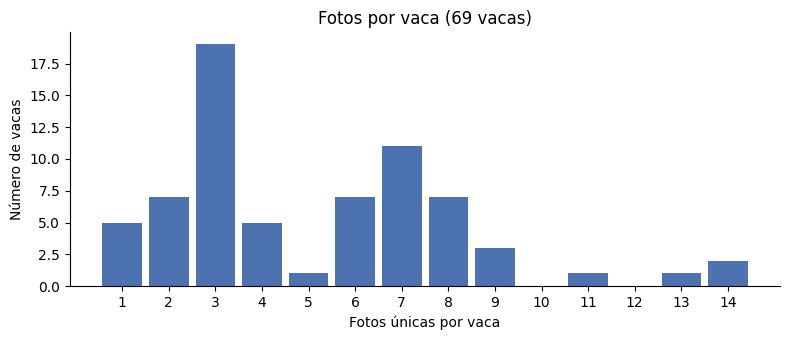

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(por_vaca, bins=range(1, por_vaca.max() + 2), align="left", rwidth=0.85, color="#4C72B0")
ax.set_xticks(range(1, por_vaca.max() + 1))
ax.set_xlabel("Fotos únicas por vaca")
ax.set_ylabel("Número de vacas")
ax.set_title(f"Fotos por vaca ({len(por_vaca)} vacas)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURAS / "fotos_por_vaca.png", dpi=200)
plt.show()

**Resultados:** La mayoría de las vacas tiene pocas fotos: 36 de las 69 tienen 4 o menos y 19 tienen exactamente 3. Solo 3 vacas tienen más de 11 fotos (una con 13 y dos con 14).

### Cruce entre fuentes

In [14]:
ids_bit, ids_fotos, ids_vms = set(bit["id_vaca"]), set(fotos["id_vaca"]), set(vms["id_vaca"])
conteos = pd.Series({
    "en la bitácora": len(ids_bit),
    "bitácora y fotos": len(ids_bit & ids_fotos),
    "bitácora y vms-3": len(ids_bit & ids_vms),
    "bitácora y ordeño": len(ids_bit & ids_ordeno),
    "bitácora, vms-3 y ordeño": len(ids_bit & ids_vms & ids_ordeno),
    "en vms-3 sin BCS de expertos": len(ids_vms - ids_bit),
})
display(conteos.to_frame("vacas"))
print("Bitácora y ordeño:", ordenar_ids(ids_bit & ids_ordeno))
print("Bitácora, vms-3 y ordeño:", ordenar_ids(ids_bit & ids_vms & ids_ordeno))
print("En vms-3 sin BCS de expertos:", ordenar_ids(ids_vms - ids_bit))

cruce = pd.DataFrame({"id_vaca": ordenar_ids(ids_bit | ids_fotos | ids_vms)})
for nombre, ids in (("bitácora", ids_bit), ("fotos", ids_fotos), ("vms-3", ids_vms), ("ordeño", ids_ordeno)):
    cruce[nombre] = np.where(cruce["id_vaca"].isin(ids), "Sí", "No")
display(cruce)

,vacas
en la bitácora,69
bitácora y fotos,69
bitácora y vms-3,13
bitácora y ordeño,12
"bitácora, vms-3 y ordeño",2
en vms-3 sin BCS de expertos,11


Bitácora y ordeño: ['1204', '1221', '1554', '1624', '1634', '2076', '2082', '6178', '8709', '8729', '8758', '8775']
Bitácora, vms-3 y ordeño: ['2082', '8709']
En vms-3 sin BCS de expertos: ['1213', '1538', '1565', '1570', '1644', '2126', '2165', '6226', '8769', '91576', '91578']


,id_vaca,bitácora,fotos,vms-3,ordeño
0,1204,Sí,Sí,No,Sí
1,1213,No,No,Sí,No
2,1221,Sí,Sí,No,Sí
3,1234,Sí,Sí,No,No
4,1240,Sí,Sí,No,No
5,1507,Sí,Sí,No,No
6,1510,Sí,Sí,No,No
7,1513,Sí,Sí,No,No
8,1516,Sí,Sí,No,No
9,1517,Sí,Sí,No,No


**Resultados:** De las 69 vacas de la bitácora, 69 tienen fotos, 13 están en `vms-3.csv` y 12 tienen datos de ordeño (1204, 1221, 1554, 1624, 1634, 2076, 2082, 6178, 8709, 8729, 8758 y 8775). 2 vacas aparecen en la bitácora, en `vms-3.csv` y en ordeño: 2082 y 8709. En `vms-3.csv` hay 11 vacas sin BCS de los expertos.

### "Evento BCS" contra el BCS de los expertos

In [15]:
if c_evento is None:
    print("vms-3.csv no tiene una columna 'Evento BCS'")
else:
    evento = vms[["id_vaca", c_evento]].rename(columns={c_evento: "evento_bcs"})
    evento["evento_bcs"] = pd.to_numeric(evento["evento_bcs"].str.replace(",", "."), errors="coerce")
    expertos = bit.groupby("id_vaca")["bcs"].agg(bcs_expertos="mean", evaluaciones="size").reset_index()
    comp = expertos.merge(evento.dropna(subset=["evento_bcs"]), on="id_vaca")
    comp["diferencia"] = (comp["evento_bcs"] - comp["bcs_expertos"]).round(2)
    display(comp.sort_values("diferencia", ascending=False).reset_index(drop=True))
    print(f"{len(comp)} vacas con ambos valores: Evento BCS mayor en {(comp['diferencia'] > 0).sum()}, "
          f"igual en {(comp['diferencia'] == 0).sum()} y menor en {(comp['diferencia'] < 0).sum()}")

,id_vaca,bcs_expertos,evaluaciones,evento_bcs,diferencia
0,8744,3.00,1,4.17,1.17
1,8799,2.50,1,3.50,1.00
2,1547,3.25,1,3.98,0.73
3,8709,2.50,1,3.22,0.72
4,6137,3.25,1,3.79,0.54
5,1567,3.00,2,3.50,0.50
6,91549,3.00,1,3.48,0.48
7,2142,3.25,1,3.50,0.25
8,1564,3.50,1,3.74,0.24
9,1532,3.25,1,3.25,0.00


12 vacas con ambos valores: Evento BCS mayor en 9, igual en 2 y menor en 1


**Resultados:** De 12 vacas con ambos valores, Evento BCS es mayor en 9, igual en 2 y menor en 1. La mayor diferencia es la de la vaca 8744 (+1.17: 4.17 contra 3.00 de los expertos).

## 2.4 Verificar la calidad de los datos

### Archivos repetidos

In [16]:
copias = len(fotos) - len(fotos.drop_duplicates(["id_vaca", "sha256"]))
numeradas = int(fotos["archivo"].str.contains(r"\(\d+\)\.", regex=True).sum())
descargas = fotos.groupby(["id_vaca", "descarga"])["sha256"].apply(frozenset)
dobles = {v: ("mismo contenido" if len(set(g.values)) == 1 else "contenido distinto")
          for v, g in descargas.groupby(level=0) if len(g) > 1}
print(f"Archivos repetidos dentro de una misma vaca: {copias}")
print(f"Archivos con nombre tipo '(1)': {numeradas}")
print(f"Vacas con más de una carpeta descargada: {len(dobles)}")
display(pd.Series(dobles, dtype=object).rename_axis("id_vaca").to_frame("carpetas"))

Archivos repetidos dentro de una misma vaca: 122
Archivos con nombre tipo '(1)': 18
Vacas con más de una carpeta descargada: 14


,carpetas
id_vaca,
1221,mismo contenido
1507,mismo contenido
1510,mismo contenido
1516,mismo contenido
1543,mismo contenido
1567,mismo contenido
1634,mismo contenido
2076,mismo contenido
2101,mismo contenido


**Resultados:** Hay 122 archivos repetidos dentro de una misma vaca y 18 nombres tipo "(1)". 14 vacas tienen más de una carpeta: en 13 el contenido es el mismo y en 1 es distinto (la vaca 2123).

### Fotos en más de una vaca

In [17]:
vacas_por_foto = (fotos.drop_duplicates(["id_vaca", "sha256"])
                  .groupby("sha256")["id_vaca"].apply(lambda s: ordenar_ids(set(s))))
compartidas = vacas_por_foto[vacas_por_foto.map(len) > 1]
grupos_compartidos = Counter(", ".join(v) for v in compartidas)
print(f"Fotos idénticas en más de una vaca: {len(compartidas)}")
display(pd.Series(grupos_compartidos, dtype=object).rename_axis("vacas").to_frame("fotos"))

Fotos idénticas en más de una vaca: 4


,fotos
vacas,
"1548, 2107",4


**Resultados:** 4 fotos idénticas aparecen en más de una vaca: 1548 y 2107.

### Consistencia de la bitácora

In [18]:
print("IDs de la bitácora sin carpeta de fotos:", ordenar_ids(ids_bit - ids_fotos))
print("Carpetas de fotos sin registro en la bitácora:", ordenar_ids(ids_fotos - ids_bit))

filas_por_id = bit["id_vaca"].value_counts()
carpetas_por_id = fotos[["id_vaca", "descarga"]].drop_duplicates()["id_vaca"].value_counts()
todos = filas_por_id.index.union(carpetas_por_id.index)
consistencia = pd.DataFrame({"filas en la bitácora": filas_por_id.reindex(todos, fill_value=0),
                             "carpetas de fotos": carpetas_por_id.reindex(todos, fill_value=0)})
distintas = consistencia[consistencia.iloc[:, 0] != consistencia.iloc[:, 1]]
print(f"IDs donde no coinciden filas y carpetas: {len(distintas)}")
display(distintas)

print(f"Horas con 'x': {(formato_hora == 'x (sin dato)').sum()} | con otro formato: {(formato_hora == 'otro formato').sum()}")
display(bit.loc[formato_hora == "otro formato", ["fila_excel", "id_vaca", "hora_original"]])
fuera = bit[bit["bcs"].isna() | (bit["bcs"] < 1) | (bit["bcs"] > 5)]
print(f"BCS vacíos o fuera de 1 a 5: {len(fuera)}")

IDs de la bitácora sin carpeta de fotos: []
Carpetas de fotos sin registro en la bitácora: []
IDs donde no coinciden filas y carpetas: 0


,filas en la bitácora,carpetas de fotos
id_vaca,,


Horas con 'x': 14 | con otro formato: 2


,fila_excel,id_vaca,hora_original
41,44,1221,13
47,50,8741,no hora


BCS vacíos o fuera de 1 a 5: 0


**Resultados:** 0 IDs de la bitácora no tienen carpeta y 0 carpetas no tienen registro en la bitácora. En 0 IDs no coinciden filas y carpetas. Hay 14 horas con "x", 2 con otro formato (filas 44 y 50) y 0 BCS vacíos o fuera de rango.

### Orientación de las fotos

In [19]:
jpg = unicas[unicas["ext"].isin([".jpg", ".jpeg"])]
giradas = jpg[jpg["orientacion"].fillna(1).astype(int) != 1]
print(f"Fotos JPG: {len(jpg)} | con orientación EXIF distinta de 1: {len(giradas)}")
display(giradas.groupby(giradas["camara"].replace("", "(sin dato)")).size().rename_axis("cámara").to_frame("fotos giradas"))

Fotos JPG: 24 | con orientación EXIF distinta de 1: 20


,fotos giradas
cámara,
samsung SM-S901U1,20


**Resultados:** De 24 fotos JPG, 20 tienen una orientación EXIF distinta de 1, todas tomadas con el Samsung SM-S901U1.

### Resumen de calidad

In [20]:
nombres_compartidas = "; ".join(f"{k} ({v})" for k, v in grupos_compartidos.items()) or "ninguna"
con_distinto = ", ".join(k for k, v in dobles.items() if v == "contenido distinto") or "ninguna"
calidad = pd.DataFrame([
    ["Archivos repetidos", f"{copias} copias; {len(dobles)} vacas con más de una carpeta; {numeradas} nombres tipo '(1)'",
     "3.2 Limpiar: dejar una sola copia por contenido"],
    ["Fotos en más de una vaca", f"{len(compartidas)} fotos idénticas: {nombres_compartidas}",
     "3.2 Limpiar: quitarlas, porque no se sabe a qué vaca pertenecen"],
    ["Carpetas con contenido distinto para una vaca", con_distinto,
     "3.2 Limpiar: no se puede saber qué fotos van con cada evaluación"],
    ["Formatos y resoluciones mezclados",
     f"{', '.join(f'{k} ({v})' for k, v in unicas['ext'].value_counts().items())}; {resolucion.nunique()} resoluciones",
     "3.5 Formatear: un solo formato antes de entrenar"],
    ["Fotos giradas", f"{len(giradas)} JPG con orientación EXIF distinta de 1",
     "3.5 Formatear: enderezarlas al convertir"],
    ["Hora en la bitácora", f"{(formato_hora == 'x (sin dato)').sum()} con 'x' y {(formato_hora == 'otro formato').sum()} con otro formato",
     "No se usa en el modelo; se conserva como registro"],
    ["Vacas con más de una evaluación", f"{len(pares)} vacas; diferencia media {dif.mean():.3f} y máxima {dif.max():.2f}",
     "3.3 Construir: definir la etiqueta de entrenamiento"],
    ["Vista de cada foto", "No viene en los nombres ni en los metadatos",
     "3.3 Construir: marcar la vista de cada foto"],
], columns=["aspecto", "evidencia", "tratamiento (fase 3)"])
with pd.option_context("display.max_colwidth", None):
    display(calidad)

,aspecto,evidencia,tratamiento (fase 3)
0,Archivos repetidos,122 copias; 14 vacas con más de una carpeta; 18 nombres tipo '(1)',3.2 Limpiar: dejar una sola copia por contenido
1,Fotos en más de una vaca,"4 fotos idénticas: 1548, 2107 (4)","3.2 Limpiar: quitarlas, porque no se sabe a qué vaca pertenecen"
2,Carpetas con contenido distinto para una vaca,2123,3.2 Limpiar: no se puede saber qué fotos van con cada evaluación
3,Formatos y resoluciones mezclados,".heic (327), .jpg (24); 7 resoluciones",3.5 Formatear: un solo formato antes de entrenar
4,Fotos giradas,20 JPG con orientación EXIF distinta de 1,3.5 Formatear: enderezarlas al convertir
5,Hora en la bitácora,14 con 'x' y 2 con otro formato,No se usa en el modelo; se conserva como registro
6,Vacas con más de una evaluación,14 vacas; diferencia media 0.125 y máxima 0.25,3.3 Construir: definir la etiqueta de entrenamiento
7,Vista de cada foto,No viene en los nombres ni en los metadatos,3.3 Construir: marcar la vista de cada foto


## Conclusión

Hay 83 evaluaciones de BCS de expertos para 69 vacas, y todas tienen fotos (351 fotos únicas). Antes de entrenar hay que dejar una sola copia de cada foto, quitar las 4 fotos compartidas por las vacas 1548 y 2107, resolver la vaca 2123, unificar el formato y la orientación, y tomar en cuenta que las clases extremas tienen pocas evaluaciones. "Evento BCS" no se usa como etiqueta y el ordeño queda solo como contexto.